# TP6. Géométrie du plan

Carnet de travail. L'énoncé complet, avec les corrigés, est sur le site :
https://cours.gclab.fr/outils-fondamentaux/tp6-geometrie-plan/

Exécutez une cellule avec Maj+Entrée. **Pensez à télécharger ce carnet avant de partir** : menu File, puis Download.


## Exercice 1.1 : la boîte à outils

Écrivez `vecteur(A, B)`, `produit_scalaire(u, v)`, `norme(u)` et `angle(u, v)`, ce
dernier en degrés.

**Résultat attendu :** `norme((3, 4))` vaut `5.0`, `produit_scalaire((1, 2), (3, 4))`
vaut `11`, `angle((1, 0), (1, 1))` vaut `45.0` à l'arrondi près, et
`angle((1, 0), (0, 1))` vaut `90.0`.


In [1]:
import math

def vecteur(A, B):
    """Vecteur AB, de A vers B."""
    return (B[0] - A[0], B[1] - A[1])

def produit_scalaire(u, v):
    return u[0] * v[0] + u[1] * v[1]

def norme(u):
    return math.hypot(u[0], u[1])

def angle(u, v):
    """Angle non orienté entre u et v, en degrés."""
    cosinus = produit_scalaire(u, v) / (norme(u) * norme(v))
    cosinus = max(-1.0, min(1.0, cosinus))
    return math.degrees(math.acos(cosinus))

print(norme((3, 4)), produit_scalaire((1, 2), (3, 4)))
print(angle((1, 0), (1, 1)), angle((1, 0), (0, 1)))
print(angle((2, 0), (2, 0)))


5.0 11
45.00000000000001 90.0
0.0


## Exercice 1.2 : la distance d'un point à une droite

La distance du point $P$ à la droite $(AB)$ vaut
$\dfrac{|\vec{AB} \times \vec{AP}|}{\|\vec{AB}\|}$, où $\times$ désigne le
**déterminant** $u_x v_y - u_y v_x$, que l'étape suivante interprète. Écrivez
`determinant(u, v)` puis `distance_point_droite(P, A, B)`.

**Résultat attendu :** la distance de l'origine à la droite passant par $(0, 1)$ et
$(1, 0)$ vaut $\sqrt{2}/2 \approx 0{,}7071$, et celle de $(3, 4)$ à l'axe des
abscisses vaut `4.0`.


In [2]:
def determinant(u, v):
    """Déterminant de (u, v), aire orientée du parallélogramme qu'ils engendrent."""
    return u[0] * v[1] - u[1] * v[0]

def distance_point_droite(P, A, B):
    AB = vecteur(A, B)
    AP = vecteur(A, P)
    return abs(determinant(AB, AP)) / norme(AB)

print(distance_point_droite((0, 0), (0, 1), (1, 0)), math.sqrt(2) / 2)
print(distance_point_droite((3, 4), (0, 0), (1, 0)))


0.7071067811865475 0.7071067811865476
4.0


## Exercice 2.1 : à gauche ou à droite ?

Écrivez `orientation(A, B, C)` qui renvoie `1` si le trajet $A \to B \to C$ tourne
à gauche, `-1` s'il tourne à droite, `0` si les trois points sont alignés.

**Résultat attendu :** `orientation((0, 0), (1, 0), (1, 1))` vaut `1`,
`orientation((0, 0), (1, 0), (1, -1))` vaut `-1`, et
`orientation((0, 0), (1, 1), (2, 2))` vaut `0`.


In [3]:
def orientation(A, B, C):
    """1 si A -> B -> C tourne à gauche, -1 à droite, 0 si alignés."""
    d = determinant(vecteur(A, B), vecteur(A, C))
    if d > 0:
        return 1
    if d < 0:
        return -1
    return 0

print(orientation((0, 0), (1, 0), (1, 1)))
print(orientation((0, 0), (1, 0), (1, -1)))
print(orientation((0, 0), (1, 1), (2, 2)))


1
-1
0


## Exercice 2.2 : l'aire d'un polygone

Un polygone est une liste de sommets dans l'ordre. Son aire vaut la moitié de la
valeur absolue de la somme des déterminants $x_i y_{i+1} - x_{i+1} y_i$ sur les
côtés consécutifs, le dernier sommet étant relié au premier : c'est la **formule du
lacet**. Écrivez `aire(polygone)`.

**Résultat attendu :** le carré unité a une aire de `1.0`, le triangle
$(0,0), (4,0), (0,3)$ une aire de `6.0`, et la maison du TP4,
`[(0, 0), (2, 0), (2, 1.5), (1, 2.5), (0, 1.5)]`, une aire de `4.0`.


In [4]:
def aire(polygone):
    """Aire d'un polygone simple donné par ses sommets dans l'ordre (formule du lacet)."""
    somme = 0
    n = len(polygone)
    for i in range(n):
        x1, y1 = polygone[i]
        x2, y2 = polygone[(i + 1) % n]
        somme = somme + (x1 * y2 - x2 * y1)
    return abs(somme) / 2

carre = [(0, 0), (1, 0), (1, 1), (0, 1)]
triangle = [(0, 0), (4, 0), (0, 3)]
maison = [(0, 0), (2, 0), (2, 1.5), (1, 2.5), (0, 1.5)]
print(aire(carre), aire(triangle), aire(maison))


1.0 6.0 4.0


## Exercice 3.1 : le test de croisement

Écrivez `se_coupent(A, B, C, D)` avec quatre appels à `orientation`. Ne traitez pas les
cas où trois points sont alignés : renvoyez `False`, et notez-le dans la docstring.

**Résultat attendu :** les diagonales du carré unité se coupent ; les segments
$[(0,0), (1, 0)]$ et $[(0, 1), (1, 1)]$, parallèles, ne se coupent pas ;
$[(0,0), (1,1)]$ et $[(2,2), (3,3)]$, alignés mais disjoints, non plus.


In [5]:
def se_coupent(A, B, C, D):
    """Vrai si les segments [AB] et [CD] se croisent franchement.

    Les cas dégénérés (trois points alignés) renvoient False.
    """
    o1 = orientation(A, B, C)
    o2 = orientation(A, B, D)
    o3 = orientation(C, D, A)
    o4 = orientation(C, D, B)
    return o1 * o2 < 0 and o3 * o4 < 0

print(se_coupent((0, 0), (1, 1), (0, 1), (1, 0)))
print(se_coupent((0, 0), (1, 0), (0, 1), (1, 1)))
print(se_coupent((0, 0), (1, 1), (2, 2), (3, 3)))


True
False
False


## Exercice 3.2 : le point d'intersection

Quand les segments se coupent, on veut souvent le point. En écrivant
$A + t\,\vec{AB} = C + u\,\vec{CD}$, on obtient un système de deux équations à deux
inconnues $t$ et $u$, que les déterminants résolvent directement :
$t = \dfrac{\vec{AC} \times \vec{CD}}{\vec{AB} \times \vec{CD}}$ et
$u = \dfrac{\vec{AC} \times \vec{AB}}{\vec{AB} \times \vec{CD}}$. Écrivez
`intersection(A, B, C, D)` qui renvoie le point, ou `None` si les segments ne se
coupent pas.

**Résultat attendu :** les diagonales du carré de côté 2 se coupent en `(1.0, 1.0)`.


In [6]:
def intersection(A, B, C, D):
    """Point d'intersection des segments [AB] et [CD], ou None."""
    AB = vecteur(A, B)
    CD = vecteur(C, D)
    denominateur = determinant(AB, CD)
    if denominateur == 0:
        return None            # parallèles ou alignés
    AC = vecteur(A, C)
    t = determinant(AC, CD) / denominateur
    u = determinant(AC, AB) / denominateur
    if 0 <= t <= 1 and 0 <= u <= 1:
        return (A[0] + t * AB[0], A[1] + t * AB[1])
    return None

print(intersection((0, 0), (2, 2), (0, 2), (2, 0)))
print(intersection((0, 0), (1, 0), (0, 1), (1, 1)))
print(intersection((0, 0), (1, 1), (2, 2), (3, 3)))


(1.0, 1.0)
None
None


## Exercice 4.1 : le lancer de rayon

Écrivez `dedans(P, polygone)`. Pour chaque côté $[S_i S_{i+1}]$, le rayon le
traverse si les deux ordonnées encadrent celle de $P$ et si l'abscisse du point de
croisement, obtenue par interpolation, est à droite de $P$.

**Résultat attendu :** dans la maison, `(1, 1)` et `(1, 2.4)` sont dedans, `(3, 1)`
et `(0.2, 2.2)` sont dehors.


In [7]:
def dedans(P, polygone):
    """Vrai si P est à l'intérieur du polygone, par lancer de rayon horizontal."""
    x, y = P
    n = len(polygone)
    interieur = False
    for i in range(n):
        x1, y1 = polygone[i]
        x2, y2 = polygone[(i + 1) % n]
        if (y1 > y) != (y2 > y):
            x_croisement = x1 + (y - y1) * (x2 - x1) / (y2 - y1)
            if x < x_croisement:
                interieur = not interieur
    return interieur

for P in ((1, 1), (1, 2.4), (3, 1), (0.2, 2.2)):
    print(P, dedans(P, maison))


(1, 1) True
(1, 2.4) True
(3, 1) False
(0.2, 2.2) False


## Exercice 4.2 : l'aire par le hasard

On peut estimer une aire sans formule : tirer des points au hasard dans un rectangle
qui contient la figure, compter ceux qui tombent dedans, et multiplier la proportion
par l'aire du rectangle. C'est la **méthode de Monte-Carlo**. Estimez ainsi l'aire de
la maison avec 200 000 points tirés dans le rectangle $[0, 2] \times [0, 2{,}5]$.

**Résultat attendu :** une valeur proche de `4.0`, à quelques centièmes près, et qui
change à chaque exécution si vous ne fixez pas la graine.


In [8]:
import random

random.seed(0)
tirages = 200_000
touches = 0
for _ in range(tirages):
    P = (random.uniform(0, 2), random.uniform(0, 2.5))
    if dedans(P, maison):
        touches = touches + 1

aire_rectangle = 2 * 2.5
print(aire_rectangle * touches / tirages)


3.994425


## Exercice 5.1 : un polygone qui n'est pas convexe

Construisez un polygone en forme de L ou d'étoile, non convexe, et vérifiez sur un
tracé que `dedans` et `aire` donnent des résultats corrects, y compris dans le creux.


4.7023
True True False


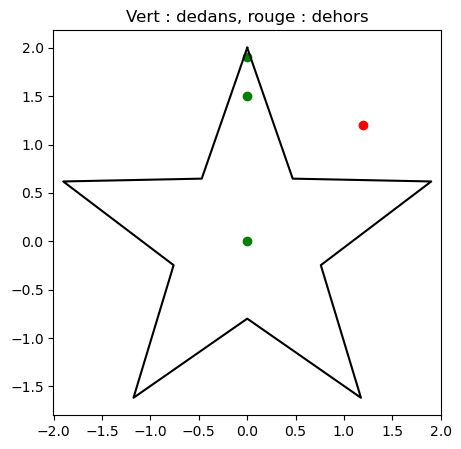

In [12]:

import math

etoile = []

for k in range(10):
    rayon = 2 if k % 2 == 0 else 0.8
    theta = math.pi / 2 + k * math.pi / 5
    etoile.append((rayon * math.cos(theta), rayon * math.sin(theta)))

print(round(aire(etoile), 4))
print(dedans((0, 0), etoile), dedans((0, 1.5), etoile), dedans((1.2, 1.2), etoile))

tracer_polygone(etoile, [(0, 0), (0, 1.5), (1.2, 1.2), (0, 1.9)])




## Exercice 6.1 : le polygone le plus proche

On dispose de plusieurs polygones, par exemple les zones d'une carte, et d'un point
cliqué. Écrivez `zone_de(P, zones)` qui renvoie l'indice de la zone contenant `P`, ou
`None`. Testez avec la maison et le carré `[(3, 0), (4, 0), (4, 1), (3, 1)]`.

**Résultat attendu :** `(1, 1)` est dans la zone `0`, `(3.5, 0.5)` dans la zone `1`,
`(2.5, 0.5)` dans aucune.


In [13]:
def zone_de(P, zones):
    """Indice de la première zone qui contient P, ou None."""
    for indice, zone in enumerate(zones):
        if dedans(P, zone):
            return indice
    return None

zones = [maison, [(3, 0), (4, 0), (4, 1), (3, 1)]]
for P in ((1, 1), (3.5, 0.5), (2.5, 0.5)):
    print(P, zone_de(P, zones))


(1, 1) 0
(3.5, 0.5) 1
(2.5, 0.5) None
